# Financial News & NLP Dataset -- Comprehensive Analysis
### Post-Annotation Deep Dive: Entities, Sectors, FinBERT Sentiment & Temporal Trends

This notebook analyzes the multi-outlet Indian financial news dataset (10,106 records, 2024-2026)
annotated with **Gemini Flash NER** (`Company`, `Sector`, `Interest`) and local GPU **FinBERT** (`Sentiment`, `Sentiment_Score`).

| Section | Content |
|---|---|
| 1 | Environment Setup & Data Loading |
| 2 | Quality Audit -- Missing Values & Deduplication |
| 3 | Dataset Overview -- Distributions & Word Counts |
| 4 | Temporal Trends -- 2024-2026 Volume & Day-of-Week |
| 5 | NER Entity & Sector Deep Dive |
| 6 | Source x Sector Coverage Heatmap |
| 7 | Sector Dynamics Over Time (Stacked Area) |
| 8 | FinBERT Sentiment Analysis (Scores, Sectors, Companies & Trends) |
| 9 | Summary Statistics & Clean Export |

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#0d1117',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#e6edf3',
    'axes.titlecolor':  '#e6edf3',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#e6edf3',
    'grid.color':       '#21262d',
    'grid.linestyle':   '--',
    'grid.alpha':       0.6,
    'font.family':      'sans-serif',
    'font.size':        11,
})
#sns.set_theme(style='darkgrid', palette='muted')

ACCENT  = '#58a6ff'
ACCENT2 = '#3fb950'
ACCENT3 = '#f78166'
PALETTE = ['#58a6ff', '#3fb950', '#f78166', '#d2a8ff', '#ffa657',
           '#79c0ff', '#56d364', '#ff7b72', '#bc8cff', '#e3b341']

print('Libraries loaded and dark theme applied.')

# SS output folder for Notes
NOTES_SS_DIR = os.path.join("..", "Notes", "2nd time", "scraping", "SS")
os.makedirs(NOTES_SS_DIR, exist_ok=True)

def save_analysis_fig(filename, dpi=150):
    for out_dir in [NOTES_SS_DIR]:
        os.makedirs(out_dir, exist_ok=True)
        plt.savefig(os.path.join(out_dir, filename), dpi=dpi, bbox_inches="tight", facecolor="#0d1117")


Libraries loaded and dark theme applied.


## 1. Data Loading

In [2]:
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
NER_CSV = os.path.join(project_root, 'Datasets', 'financial_news_ner_annotated.csv')
RAW_CSV = os.path.join(project_root, 'Datasets', 'scraped_financial_news.csv')

if os.path.exists(NER_CSV):
    df = pd.read_csv(NER_CSV)
else:
    chk = os.path.join(project_root, 'Datasets', 'scraped_financial_news_ner_checkpoint.csv')
    if os.path.exists(chk):
        df = pd.read_csv(chk)
        print(f'NER file not ready -- loaded checkpoint: {chk}')
    else:
        df = pd.read_csv(RAW_CSV)
        print(f'Loaded raw dataset (NER not run yet): {RAW_CSV}')

print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head(5)

Shape: (10106, 13)
Columns: ['Headlines', 'Article', 'Published_At', 'Source', 'Category', 'URL', 'Word_Count', 'Company', 'Sector', 'Interest', 'Sentiment', 'Sentiment_Score', 'Sentiment_Confidence']


,Headlines,Article,Published_At,Source,Category,URL,Word_Count,Company,Sector,Interest,Sentiment,Sentiment_Score,Sentiment_Confidence
0,HDFC Bank goes live with NPCI-developed UPI in...,HDFC Bank goes live with NPCI-developed UPI in...,2024-01-01 08:00:00,Business Standard,financial_rss,https://news.google.com/rss/articles/CBMi1gFBV...,12,HDFC Bank,Banking,1,Neutral,0.0807,0.9024
1,Lite Bite Foods culminates 2023 with 10 launch...,Lite Bite Foods culminates 2023 with 10 launch...,2024-01-01 08:00:00,ET HospitalityWorld,financial_rss,https://news.google.com/rss/articles/CBMi_wFBV...,16,Lite Bite Foods,FMCG,0,Positive,0.8365,0.8436
2,Investors need to have a balanced approach thi...,Investors need to have a balanced approach thi...,2024-01-01 08:00:00,Livemint,financial_rss,https://news.google.com/rss/articles/CBMivAFBV...,9,NaN,Macro / Economy,1,Neutral,0.2166,0.7565
3,India to remain fastest-growing major economy ...,India to remain fastest-growing major economy ...,2024-01-01 08:00:00,ET EnergyWorld,financial_rss,https://news.google.com/rss/articles/CBMiwgFBV...,9,NaN,Macro / Economy,1,Positive,0.8253,0.8379
4,10 best small cap mutual funds that have given...,10 best small cap mutual funds that have given...,2024-01-01 08:00:00,Livemint,financial_rss,https://news.google.com/rss/articles/CBMi1AFBV...,14,NaN,Financial Services,0,Positive,0.4878,0.5027


## 2. Quality Audit -- Missing Values and Duplicates

In [3]:
print('=' * 60)
print('QUALITY AUDIT')
print('=' * 60)

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
audit = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print('Missing Values:')
has_missing = audit['Missing Count'].sum() > 0
print(audit[audit['Missing Count'] > 0].to_string() if has_missing else '  No missing values.')

total_dupes = df.duplicated().sum()
url_dupes = df.duplicated(subset=['URL']).sum() if 'URL' in df.columns else 0
print(f'Full-row duplicates : {total_dupes}')
print(f'URL duplicates       : {url_dupes}')

initial_len = len(df)
if url_dupes > 0:
    df = df.drop_duplicates(subset=['URL'], keep='first')
    print(f'Removed {url_dupes} URL-duplicate rows. Rows: {initial_len} -> {len(df)}')
elif total_dupes > 0:
    df = df.drop_duplicates(keep='first')
    print(f'Removed {total_dupes} duplicate rows. Rows: {initial_len} -> {len(df)}')
else:
    print('No duplicates found -- dataset is clean.')

for col, fill in [('Company', 'None'), ('Sector', 'None'), ('Interest', 0)]:
    if col in df.columns and df[col].isnull().sum() > 0:
        n = df[col].isnull().sum()
        df[col] = df[col].fillna(fill)
        print(f'Filled {n} missing {col!r} values with default.')

if 'Published_At' in df.columns:
    df['Published_At'] = pd.to_datetime(df['Published_At'], errors='coerce')
    df['Month']     = df['Published_At'].dt.to_period('M')
    df['Year']      = df['Published_At'].dt.year
    df['DayOfWeek'] = df['Published_At'].dt.day_name()

if 'Interest' in df.columns:
    df['Interest'] = df['Interest'].astype(int)

print(f'Clean dataset shape: {df.shape}')
df.info()

QUALITY AUDIT
Missing Values:
         Missing Count  Missing %
Company           4257      42.12
Sector             530       5.24


Full-row duplicates : 0
URL duplicates       : 0
No duplicates found -- dataset is clean.
Filled 4257 missing 'Company' values with default.
Filled 530 missing 'Sector' values with default.
Clean dataset shape: (10106, 16)
<class 'pandas.DataFrame'>
RangeIndex: 10106 entries, 0 to 10105
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Headlines             10106 non-null  str           
 1   Article               10106 non-null  str           
 2   Published_At          10106 non-null  datetime64[us]
 3   Source                10106 non-null  str           
 4   Category              10106 non-null  str           
 5   URL                   10106 non-null  str           
 6   Word_Count            10106 non-null  int64         
 7   Company               10106 non-null  str           
 8   Sector                10106 non-null  str           
 9   Interest              10106 non-null

## 3. Dataset Overview -- Distributions

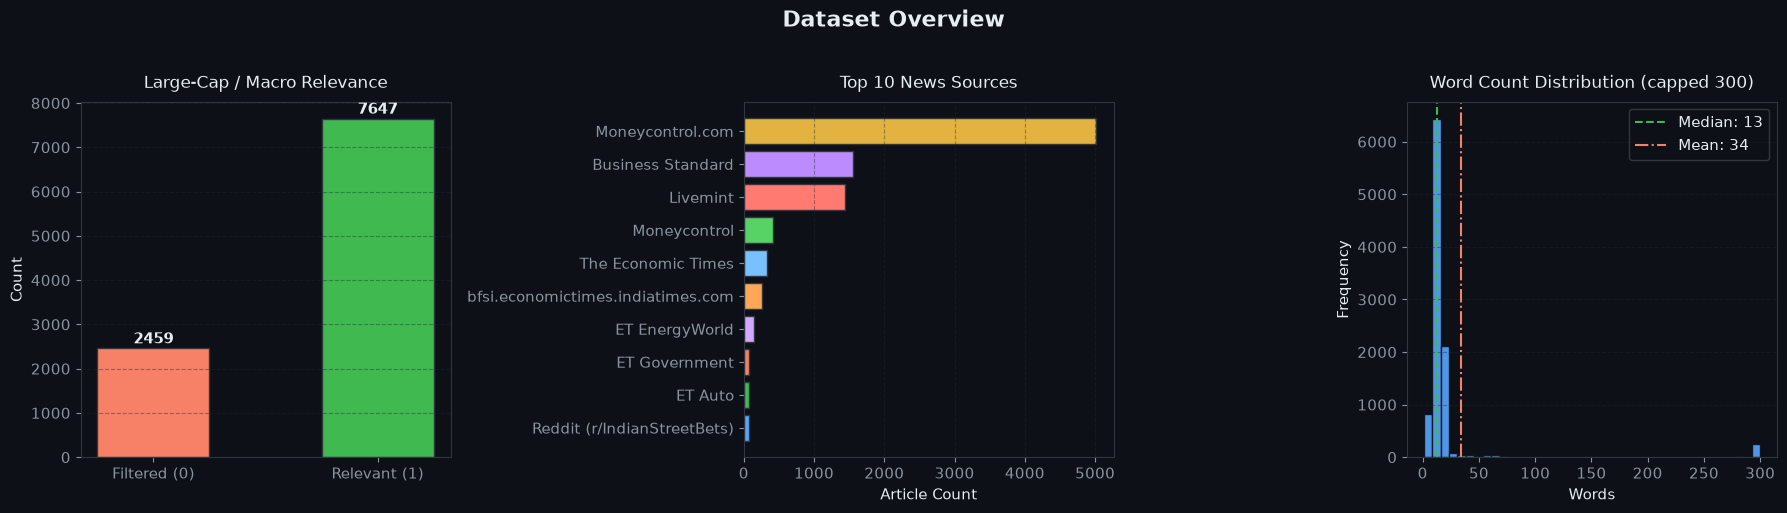

In [4]:
has_ner = 'Interest' in df.columns and 'Sector' in df.columns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Dataset Overview', fontsize=16, fontweight='bold', color='#e6edf3', y=1.02)

# Panel 1: Interest distribution
ax = axes[0]
if has_ner:
    interest_counts = df['Interest'].value_counts().sort_index()
    labels = ['Filtered (0)', 'Relevant (1)']
    clrs = [ACCENT3, ACCENT2]
    bars = ax.bar(labels, interest_counts.values, color=clrs, width=0.5, edgecolor='#30363d')
    for bar, val in zip(bars, interest_counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30, str(val),
                ha='center', va='bottom', fontweight='bold', color='#e6edf3')
    ax.set_title('Large-Cap / Macro Relevance', fontsize=12, pad=10)
    ax.set_ylabel('Count')
    ax.grid(axis='y', alpha=0.4)
else:
    ax.text(0.5, 0.5, 'NER not yet available', ha='center', va='center',
            transform=ax.transAxes, color='#8b949e', fontsize=13)
    ax.set_title('Relevance', fontsize=12)

# Panel 2: Source distribution
ax = axes[1]
src = df['Source'].value_counts().head(10)
ax.barh(src.index[::-1], src.values[::-1], color=PALETTE[:len(src)], edgecolor='#30363d')
ax.set_title('Top 10 News Sources', fontsize=12, pad=10)
ax.set_xlabel('Article Count')
ax.grid(axis='x', alpha=0.4)

# Panel 3: Word count
ax = axes[2]
wc = df['Word_Count'].clip(upper=300)
ax.hist(wc, bins=40, color=ACCENT, edgecolor='#0d1117', alpha=0.9)
med = df['Word_Count'].median()
mn  = df['Word_Count'].mean()
ax.axvline(med, color=ACCENT2, linestyle='--', linewidth=1.5, label=f'Median: {med:.0f}')
ax.axvline(mn,  color=ACCENT3, linestyle='-.', linewidth=1.5, label=f'Mean: {mn:.0f}')
ax.set_title('Word Count Distribution (capped 300)', fontsize=12, pad=10)
ax.set_xlabel('Words')
ax.set_ylabel('Frequency')
ax.legend(framealpha=0.2)
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
save_analysis_fig('analysis_overview.png')


## 4. Temporal Trends

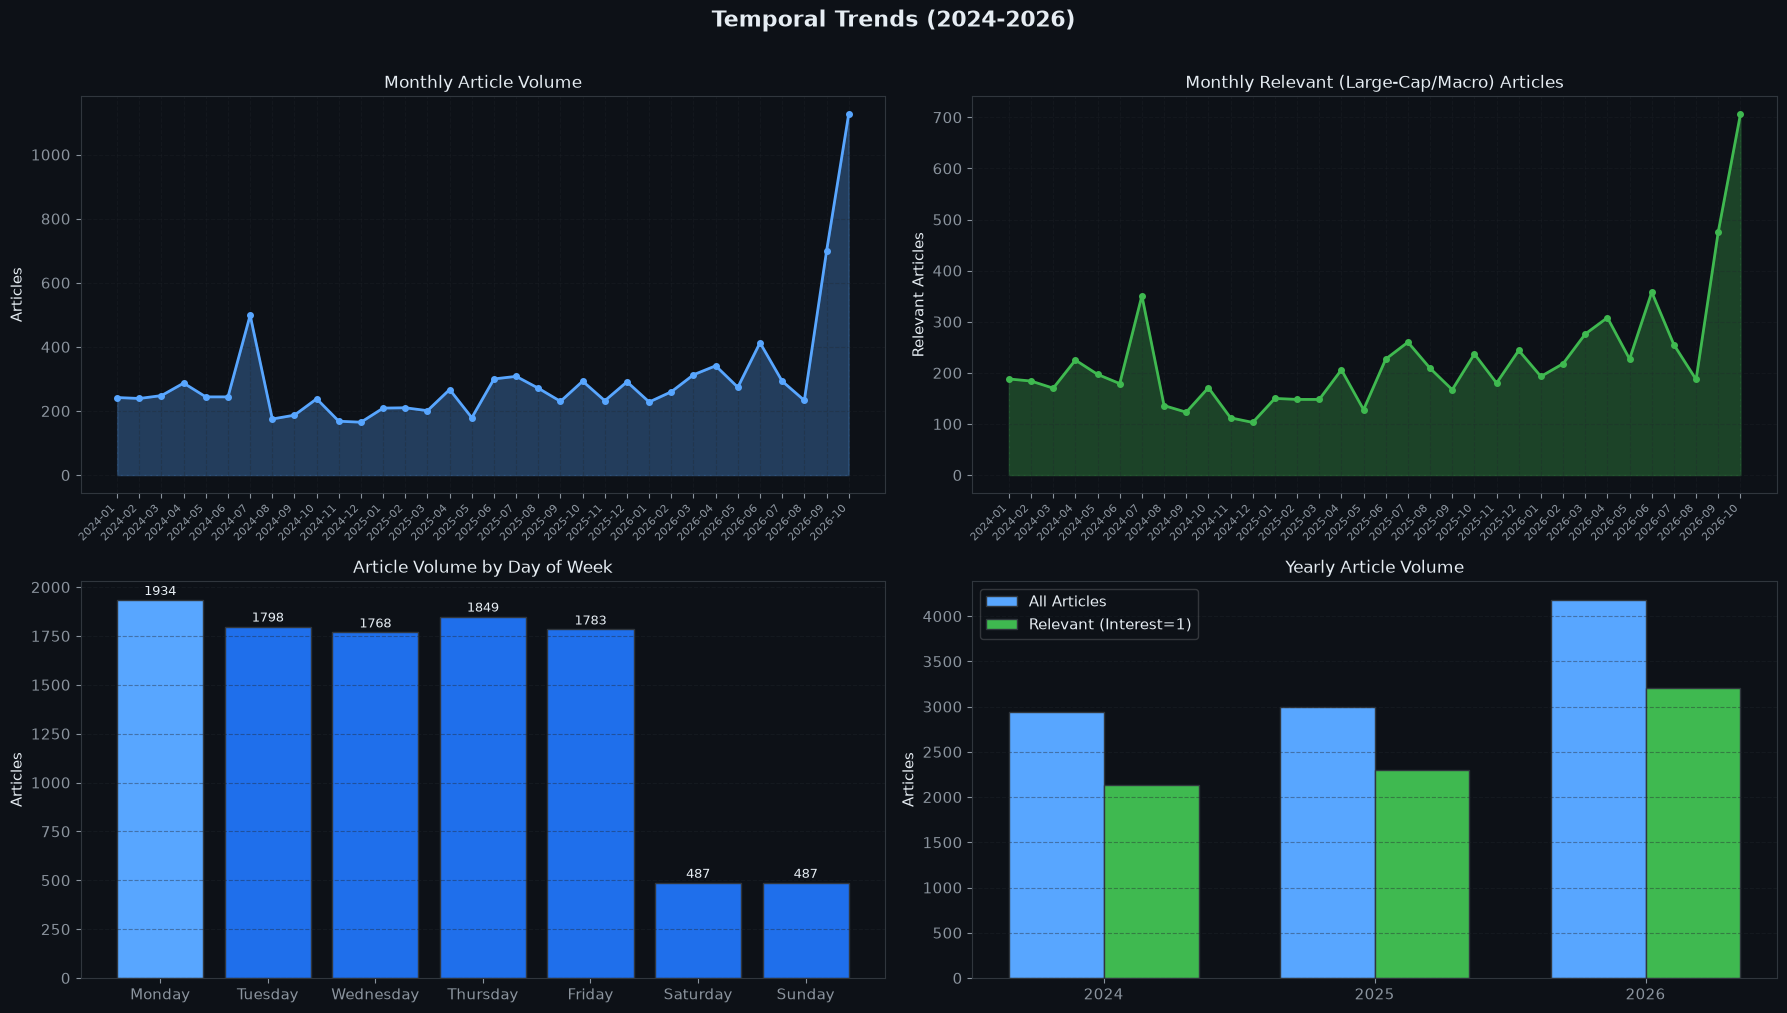

In [5]:
if 'Month' not in df.columns:
    print('No Published_At column. Skipping temporal analysis.')
else:
    fig, axes = plt.subplots(2, 2, figsize=(18, 10))
    fig.suptitle('Temporal Trends (2024-2026)', fontsize=16, fontweight='bold', color='#e6edf3', y=1.01)

    # Monthly volume
    ax = axes[0, 0]
    monthly = df.groupby('Month').size().reset_index(name='count')
    monthly['Month_str'] = monthly['Month'].astype(str)
    ax.fill_between(range(len(monthly)), monthly['count'], alpha=0.3, color=ACCENT)
    ax.plot(range(len(monthly)), monthly['count'], color=ACCENT, linewidth=2, marker='o', markersize=4)
    ax.set_xticks(range(len(monthly)))
    ax.set_xticklabels(monthly['Month_str'], rotation=45, ha='right', fontsize=8)
    ax.set_title('Monthly Article Volume', fontsize=12)
    ax.set_ylabel('Articles')
    ax.grid(True, alpha=0.3)

    # Monthly relevant
    ax = axes[0, 1]
    if has_ner:
        monthly_rel = df[df['Interest'] == 1].groupby('Month').size().reset_index(name='relevant')
        monthly_rel['Month_str'] = monthly_rel['Month'].astype(str)
        ax.fill_between(range(len(monthly_rel)), monthly_rel['relevant'], alpha=0.3, color=ACCENT2)
        ax.plot(range(len(monthly_rel)), monthly_rel['relevant'], color=ACCENT2, linewidth=2, marker='o', markersize=4)
        ax.set_xticks(range(len(monthly_rel)))
        ax.set_xticklabels(monthly_rel['Month_str'], rotation=45, ha='right', fontsize=8)
        ax.set_title('Monthly Relevant (Large-Cap/Macro) Articles', fontsize=12)
        ax.set_ylabel('Relevant Articles')
        ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'NER not yet available', ha='center', va='center',
                transform=ax.transAxes, color='#8b949e', fontsize=13)
        ax.set_title('Monthly Relevant Articles', fontsize=12)

    # Day of week
    ax = axes[1, 0]
    dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    dow_counts = df['DayOfWeek'].value_counts().reindex(dow_order, fill_value=0)
    max_val = dow_counts.max()
    clrs_dow = [ACCENT if v == max_val else '#1f6feb' for v in dow_counts.values]
    bars = ax.bar(dow_order, dow_counts.values, color=clrs_dow, edgecolor='#30363d')
    for bar, val in zip(bars, dow_counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, str(val),
                ha='center', va='bottom', fontsize=9, color='#e6edf3')
    ax.set_title('Article Volume by Day of Week', fontsize=12)
    ax.set_ylabel('Articles')
    ax.grid(axis='y', alpha=0.4)

    # Yearly
    ax = axes[1, 1]
    yearly = df.groupby('Year').size()
    x = list(range(len(yearly)))
    width = 0.35
    if has_ner:
        yearly_rel = df[df['Interest'] == 1].groupby('Year').size()
        ax.bar([v - width/2 for v in x], yearly.values, width, label='All Articles', color=ACCENT, edgecolor='#30363d')
        ax.bar([v + width/2 for v in x], yearly_rel.reindex(yearly.index, fill_value=0).values,
               width, label='Relevant (Interest=1)', color=ACCENT2, edgecolor='#30363d')
        ax.legend(framealpha=0.2)
    else:
        ax.bar(x, yearly.values, color=ACCENT, edgecolor='#30363d')
    ax.set_xticks(x)
    ax.set_xticklabels([str(y) for y in yearly.index])
    ax.set_title('Yearly Article Volume', fontsize=12)
    ax.set_ylabel('Articles')
    ax.grid(axis='y', alpha=0.4)

    plt.tight_layout()
    save_analysis_fig('analysis_temporal.png')
    plt.show()

## 5. NER Deep Dive -- Sector and Company Analysis

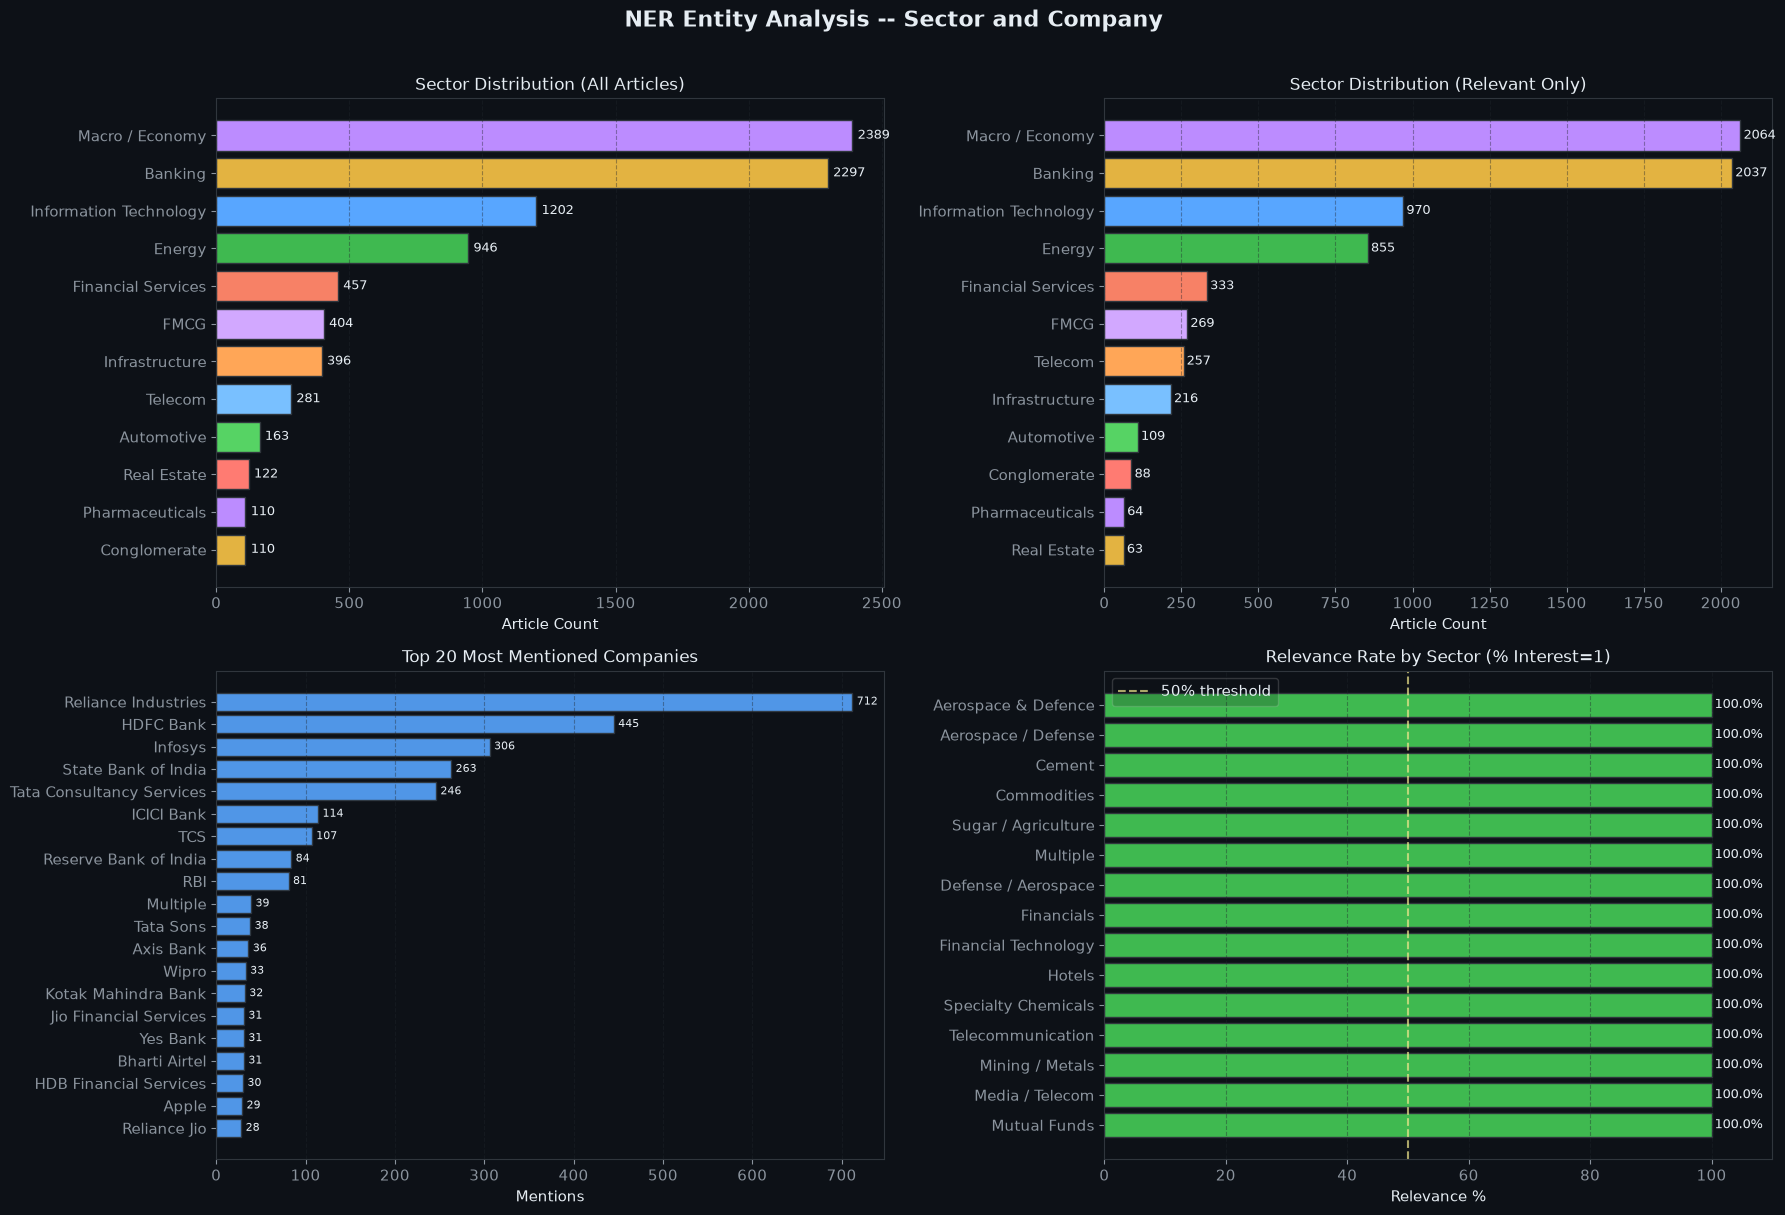

In [6]:
if not has_ner:
    print('NER columns not present. Skipping entity analysis.')
else:
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle('NER Entity Analysis -- Sector and Company', fontsize=16,
                 fontweight='bold', color='#e6edf3', y=1.01)

    # Sector all
    ax = axes[0, 0]
    sector_counts = df['Sector'].replace('None', np.nan).dropna().value_counts().head(12)
    ax.barh(sector_counts.index[::-1], sector_counts.values[::-1],
            color=PALETTE[:len(sector_counts)][::-1], edgecolor='#30363d')
    for i, val in enumerate(sector_counts.values[::-1]):
        ax.text(val + 20, i, str(val), va='center', fontsize=9, color='#e6edf3')
    ax.set_title('Sector Distribution (All Articles)', fontsize=12)
    ax.set_xlabel('Article Count')
    ax.grid(axis='x', alpha=0.4)

    # Sector relevant only
    ax = axes[0, 1]
    df_rel = df[df['Interest'] == 1]
    sector_rel = df_rel['Sector'].replace('None', np.nan).dropna().value_counts().head(12)
    ax.barh(sector_rel.index[::-1], sector_rel.values[::-1],
            color=PALETTE[:len(sector_rel)][::-1], edgecolor='#30363d')
    for i, val in enumerate(sector_rel.values[::-1]):
        ax.text(val + 10, i, str(val), va='center', fontsize=9, color='#e6edf3')
    ax.set_title('Sector Distribution (Relevant Only)', fontsize=12)
    ax.set_xlabel('Article Count')
    ax.grid(axis='x', alpha=0.4)

    # Top companies
    ax = axes[1, 0]
    company_counts = df['Company'].replace('None', np.nan).dropna().value_counts().head(20)
    ax.barh(company_counts.index[::-1], company_counts.values[::-1],
            color=ACCENT, edgecolor='#30363d', alpha=0.9)
    for i, val in enumerate(company_counts.values[::-1]):
        ax.text(val + 5, i, str(val), va='center', fontsize=8, color='#e6edf3')
    ax.set_title('Top 20 Most Mentioned Companies', fontsize=12)
    ax.set_xlabel('Mentions')
    ax.grid(axis='x', alpha=0.4)

    # Relevance rate by sector
    ax = axes[1, 1]
    sector_total = df['Sector'].replace('None', np.nan).dropna().value_counts()
    sector_rel_c = df_rel['Sector'].replace('None', np.nan).dropna().value_counts()
    rel_rate = (sector_rel_c / sector_total * 100).dropna().sort_values(ascending=False).head(15)
    bar_clrs = [ACCENT2 if v >= 60 else ACCENT if v >= 30 else ACCENT3 for v in rel_rate.values]
    ax.barh(rel_rate.index[::-1], rel_rate.values[::-1], color=bar_clrs[::-1], edgecolor='#30363d')
    ax.axvline(50, color='#f0e68c', linestyle='--', linewidth=1.5, alpha=0.7, label='50% threshold')
    for i, val in enumerate(rel_rate.values[::-1]):
        ax.text(val + 0.5, i, f'{val:.1f}%', va='center', fontsize=9, color='#e6edf3')
    ax.set_title('Relevance Rate by Sector (% Interest=1)', fontsize=12)
    ax.set_xlabel('Relevance %')
    ax.set_xlim(0, 110)
    ax.legend(framealpha=0.2)
    ax.grid(axis='x', alpha=0.4)

    plt.tight_layout()
    save_analysis_fig('analysis_ner.png')
    plt.show()

## 6. Source x Sector Heatmap

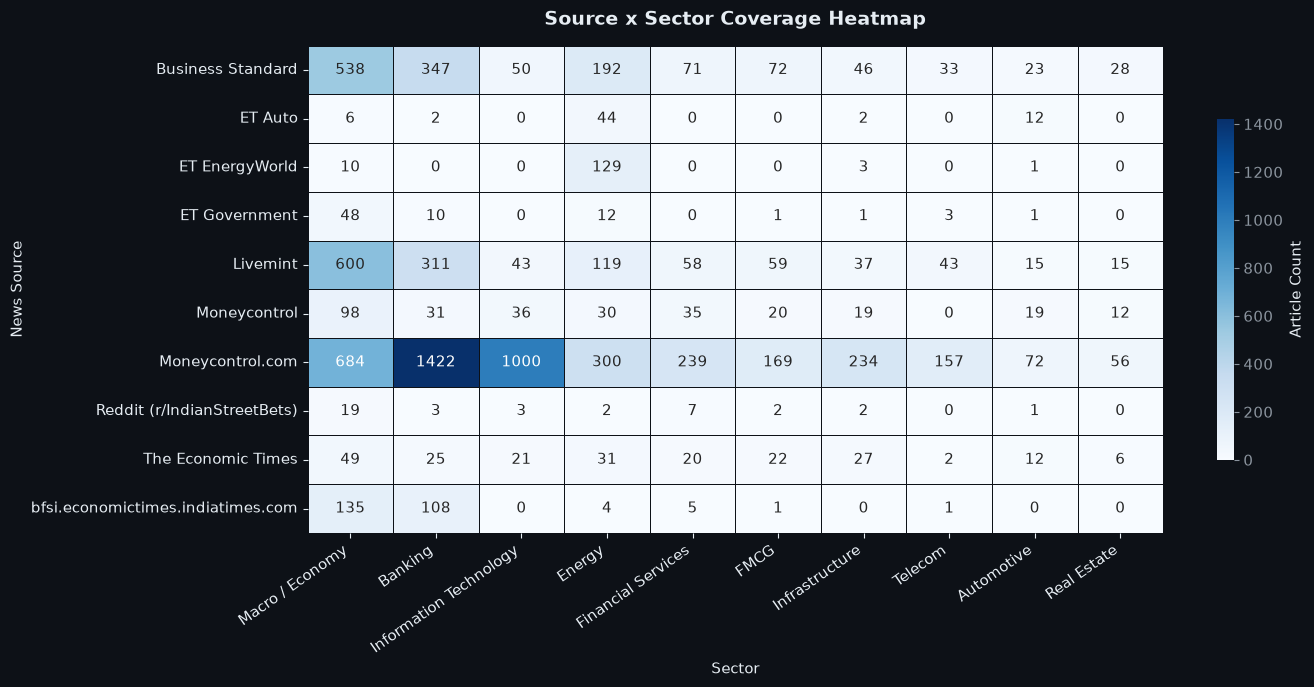

In [7]:
if not has_ner:
    print('Skipping -- NER not available.')
else:
    top_sources = df['Source'].value_counts().head(10).index
    top_sectors = df['Sector'].replace('None', np.nan).dropna().value_counts().head(10).index

    pivot = (
        df[df['Source'].isin(top_sources) & df['Sector'].isin(top_sectors)]
        .groupby(['Source', 'Sector']).size().unstack(fill_value=0)
    )
    pivot = pivot.reindex(columns=top_sectors, fill_value=0)

    fig, ax = plt.subplots(figsize=(14, 7))
    fig.patch.set_facecolor('#0d1117')
    sns.heatmap(pivot, ax=ax, cmap='Blues', annot=True, fmt='d',
                linewidths=0.5, linecolor='#0d1117',
                cbar_kws={'shrink': 0.7, 'label': 'Article Count'})
    ax.set_title('Source x Sector Coverage Heatmap', fontsize=14, pad=15,
                 fontweight='bold', color='#e6edf3')
    ax.set_xlabel('Sector', fontsize=11)
    ax.set_ylabel('News Source', fontsize=11)
    ax.tick_params(colors='#e6edf3')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    save_analysis_fig('analysis_source_sector_heatmap.png')
    plt.show()

## 7. Sector Trends Over Time (Stacked Area)

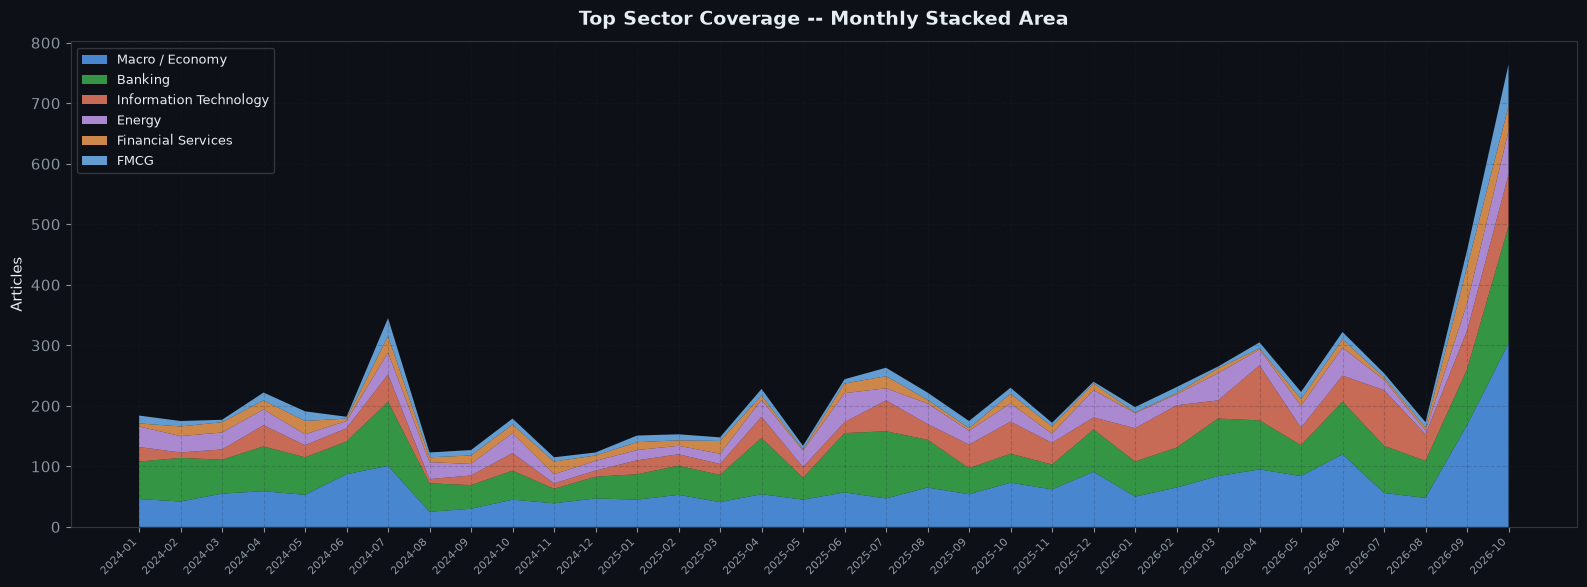

In [8]:
if not has_ner or 'Month' not in df.columns:
    print('Skipping -- NER or date data not available.')
else:
    top_sectors_list = df['Sector'].replace('None', np.nan).dropna().value_counts().head(6).index.tolist()
    df_sec = df[df['Sector'].isin(top_sectors_list)].copy()
    sec_monthly = (
        df_sec.groupby(['Month', 'Sector']).size().unstack(fill_value=0)
        .reindex(columns=top_sectors_list, fill_value=0)
    )
    sec_monthly.index = sec_monthly.index.astype(str)

    fig, ax = plt.subplots(figsize=(16, 6))
    fig.patch.set_facecolor('#0d1117')
    ax.stackplot(range(len(sec_monthly)), sec_monthly.T.values,
                 labels=top_sectors_list, colors=PALETTE[:len(top_sectors_list)], alpha=0.8)
    ax.set_xticks(range(len(sec_monthly)))
    ax.set_xticklabels(sec_monthly.index, rotation=45, ha='right', fontsize=8)
    ax.set_title('Top Sector Coverage -- Monthly Stacked Area', fontsize=14, fontweight='bold', pad=12)
    ax.set_ylabel('Articles')
    ax.legend(loc='upper left', framealpha=0.2, fontsize=9)
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    save_analysis_fig('analysis_sector_trends.png')
    plt.show()

## 8. FinBERT Sentiment Analysis

Comprehensive analysis of market sentiment evaluated locally by **`ProsusAI/finbert`** on the RTX 5050 GPU:
- **Sentiment Classification**: `Positive`, `Negative`, `Neutral`
- **Continuous Sentiment Score**: Signed range from `-1.0` (strongly bearish) to `+1.0` (strongly bullish)
- **Sector & Entity Alignment**: Sectoral mood and sentiment for top-mentioned Nifty 50 companies
- **Temporal Trajectory**: Monthly sentiment momentum across 2024-2026

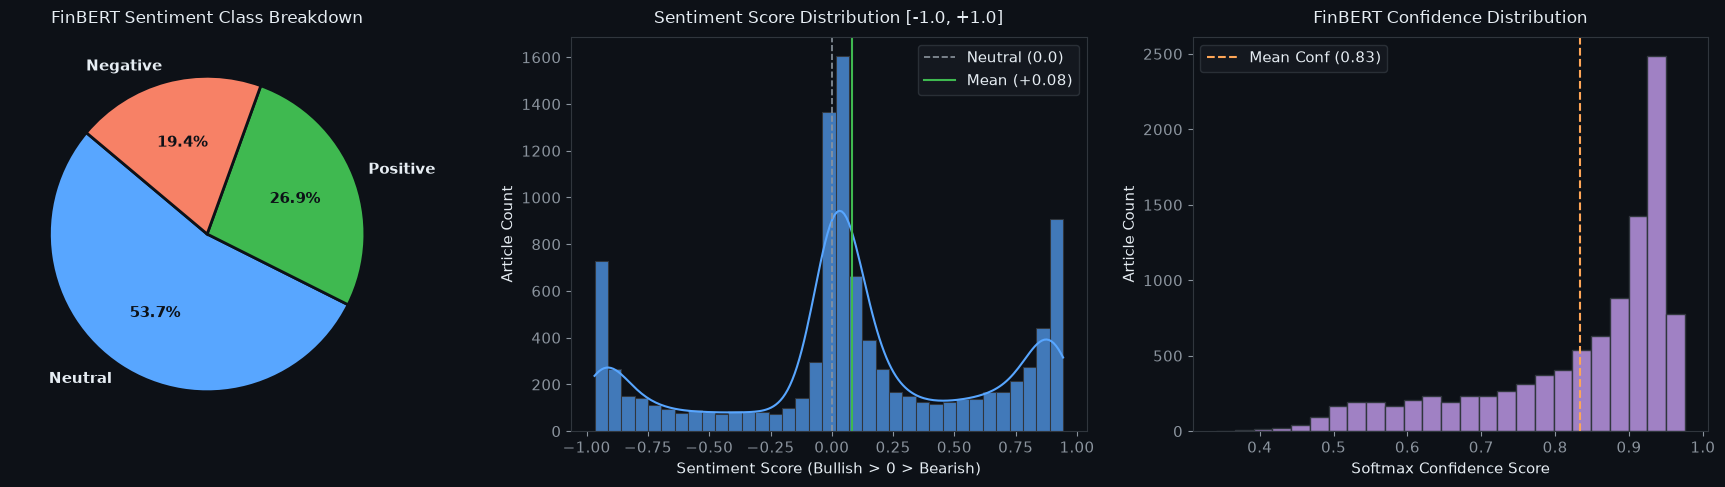

In [9]:
has_sentiment = 'Sentiment' in df.columns and 'Sentiment_Score' in df.columns

if has_sentiment:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # 1. Sentiment Class Breakdown
    sent_counts = df['Sentiment'].value_counts()
    sent_colors = {'Positive': ACCENT2, 'Neutral': ACCENT, 'Negative': ACCENT3}
    colors_list = [sent_colors.get(k, ACCENT) for k in sent_counts.index]
    
    ax = axes[0]
    wedges, texts, autotexts = ax.pie(
        sent_counts.values,
        labels=sent_counts.index,
        autopct='%1.1f%%',
        colors=colors_list,
        startangle=140,
        textprops={'color': '#e6edf3', 'fontsize': 11, 'fontweight': 'bold'},
        wedgeprops={'edgecolor': '#0d1117', 'linewidth': 2}
    )
    for at in autotexts:
        at.set_color('#0d1117')
        at.set_fontsize(11)
        at.set_fontweight('bold')
    ax.set_title('FinBERT Sentiment Class Breakdown', fontsize=12, pad=10)
    
    # 2. Continuous Sentiment Score Distribution
    ax = axes[1]
    sns.histplot(
        df['Sentiment_Score'],
        bins=35,
        kde=True,
        ax=ax,
        color=ACCENT,
        edgecolor='#30363d',
        alpha=0.7
    )
    mean_score = df['Sentiment_Score'].mean()
    median_score = df['Sentiment_Score'].median()
    ax.axvline(0.0, color='#8b949e', linestyle='--', linewidth=1.2, label='Neutral (0.0)')
    ax.axvline(mean_score, color=ACCENT2, linestyle='-', linewidth=1.5, label=f'Mean ({mean_score:+.2f})')
    ax.set_title('Sentiment Score Distribution [-1.0, +1.0]', fontsize=12, pad=10)
    ax.set_xlabel('Sentiment Score (Bullish > 0 > Bearish)')
    ax.set_ylabel('Article Count')
    ax.legend(facecolor='#161b22', edgecolor='#30363d', labelcolor='#e6edf3', loc='upper right')
    
    # 3. Model Confidence Distribution
    ax = axes[2]
    if 'Sentiment_Confidence' in df.columns:
        sns.histplot(
            df['Sentiment_Confidence'],
            bins=25,
            ax=ax,
            color='#d2a8ff',
            edgecolor='#30363d',
            alpha=0.75
        )
        conf_mean = df['Sentiment_Confidence'].mean()
        ax.axvline(conf_mean, color='#ffa657', linestyle='--', linewidth=1.5, label=f'Mean Conf ({conf_mean:.2f})')
        ax.set_title('FinBERT Confidence Distribution', fontsize=12, pad=10)
        ax.set_xlabel('Softmax Confidence Score')
        ax.set_ylabel('Article Count')
        ax.legend(facecolor='#161b22', edgecolor='#30363d', labelcolor='#e6edf3')
    
    plt.tight_layout()
    save_analysis_fig('analysis_sentiment_distribution.png')
    plt.show()


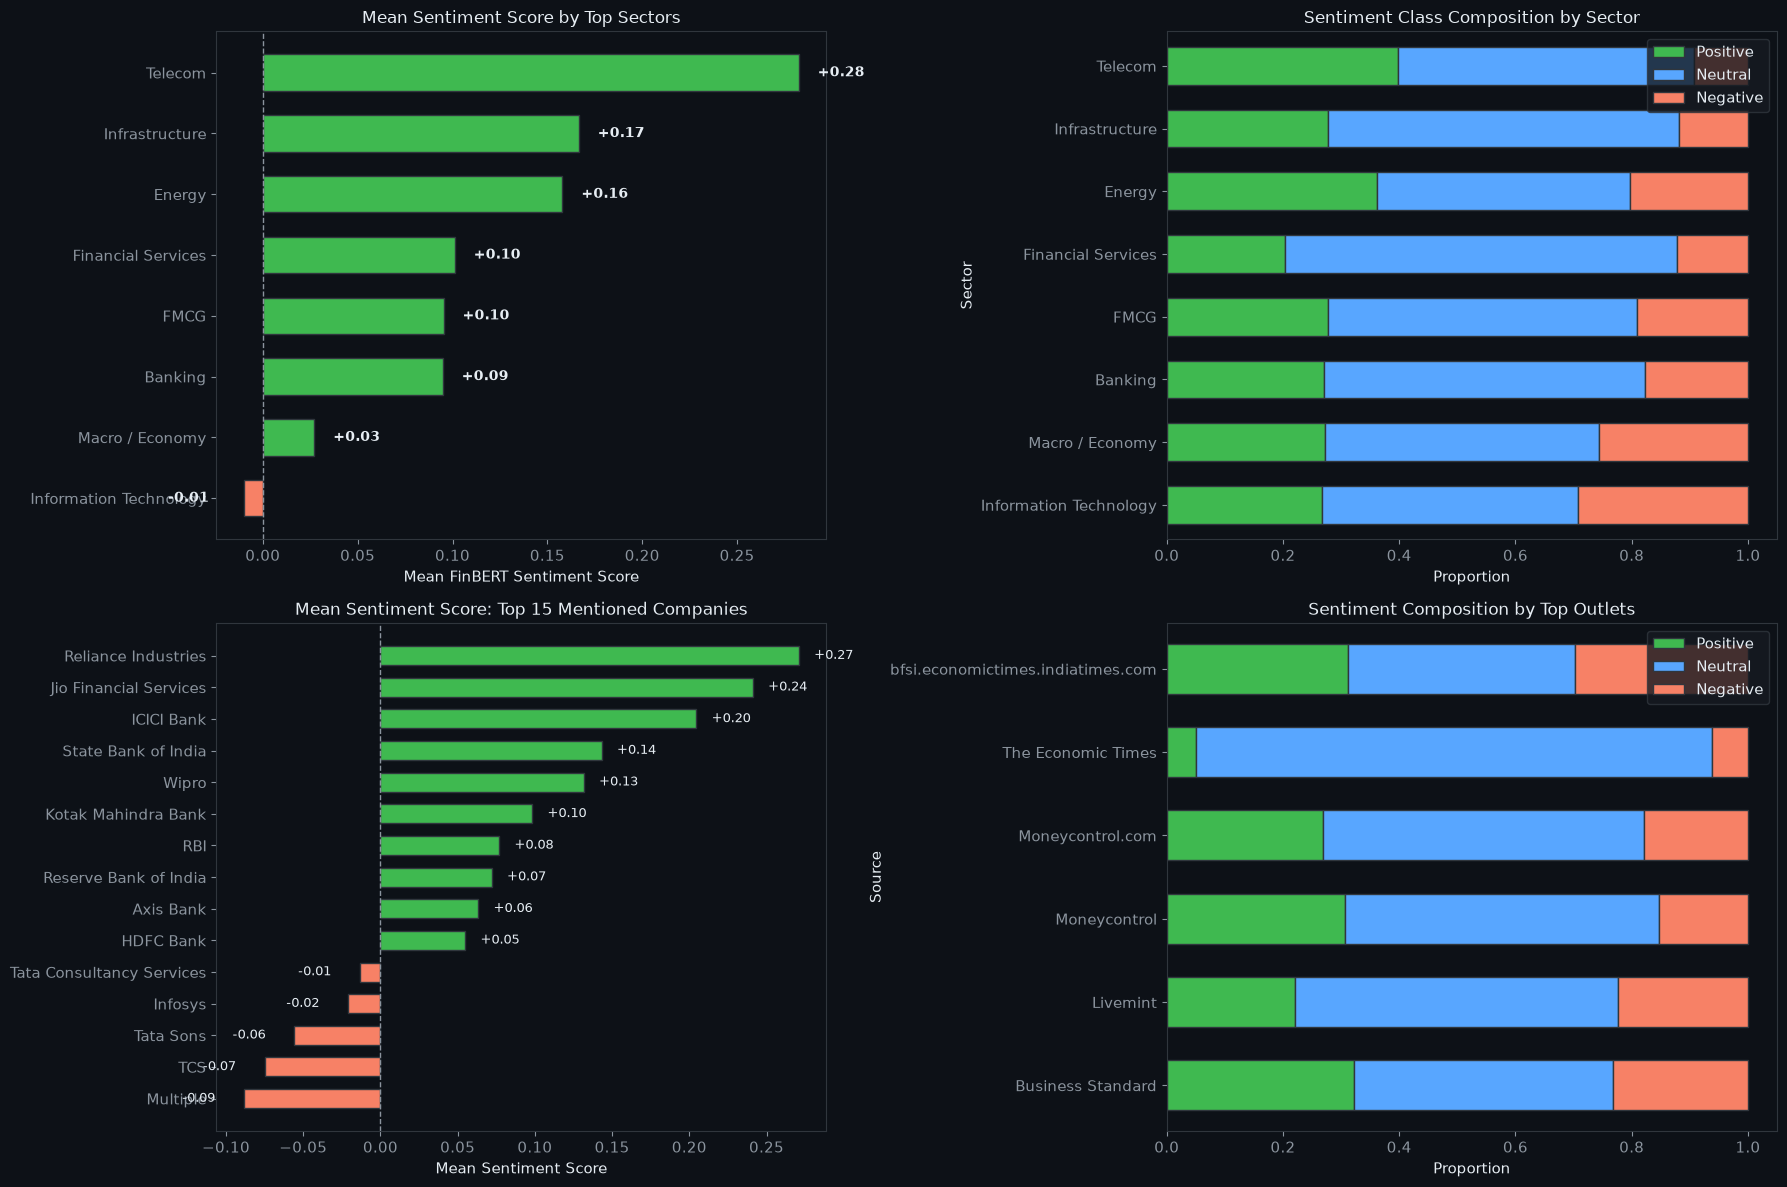

In [10]:
if has_sentiment and has_ner:
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    
    # Filter to known sectors
    sec_df = df[df['Sector'].notna() & (df['Sector'] != 'None') & (df['Sector'] != '')]
    top_sectors = sec_df['Sector'].value_counts().head(8).index.tolist()
    sec_top = sec_df[sec_df['Sector'].isin(top_sectors)]
    
    # 1. Mean Sentiment Score by Sector
    ax = axes[0, 0]
    sec_means = sec_top.groupby('Sector')['Sentiment_Score'].mean().sort_values(ascending=True)
    bar_colors = [ACCENT2 if v >= 0 else ACCENT3 for v in sec_means.values]
    bars = ax.barh(sec_means.index, sec_means.values, color=bar_colors, edgecolor='#30363d', height=0.6)
    ax.axvline(0.0, color='#8b949e', linestyle='--', linewidth=1)
    for bar in bars:
        w = bar.get_width()
        offset = 0.01 if w >= 0 else -0.04
        ax.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:+.2f}', va='center', fontsize=10, color='#e6edf3', fontweight='bold')
    ax.set_title('Mean Sentiment Score by Top Sectors', fontsize=12)
    ax.set_xlabel('Mean FinBERT Sentiment Score')
    
    # 2. Sentiment Composition by Top Sectors (100% Stacked Bar)
    ax = axes[0, 1]
    sec_comp = pd.crosstab(sec_top['Sector'], sec_top['Sentiment'], normalize='index')
    for col in ['Positive', 'Neutral', 'Negative']:
        if col not in sec_comp.columns:
            sec_comp[col] = 0.0
    sec_comp = sec_comp[['Positive', 'Neutral', 'Negative']].loc[sec_means.index]
    sec_comp.plot(
        kind='barh',
        stacked=True,
        ax=ax,
        color=[ACCENT2, ACCENT, ACCENT3],
        edgecolor='#30363d',
        width=0.6
    )
    ax.set_title('Sentiment Class Composition by Sector', fontsize=12)
    ax.set_xlabel('Proportion')
    ax.legend(facecolor='#161b22', edgecolor='#30363d', labelcolor='#e6edf3', loc='upper right')
    
    # 3. Top 15 Companies Mean Sentiment Score
    ax = axes[1, 0]
    com_df = df[df['Company'].notna() & (df['Company'] != 'None') & (df['Company'] != '')]
    top_coms = com_df['Company'].value_counts().head(15).index.tolist()
    com_means = com_df[com_df['Company'].isin(top_coms)].groupby('Company')['Sentiment_Score'].mean().sort_values(ascending=True)
    c_colors = [ACCENT2 if v >= 0 else ACCENT3 for v in com_means.values]
    c_bars = ax.barh(com_means.index, com_means.values, color=c_colors, edgecolor='#30363d', height=0.6)
    ax.axvline(0.0, color='#8b949e', linestyle='--', linewidth=1)
    for bar in c_bars:
        w = bar.get_width()
        offset = 0.01 if w >= 0 else -0.04
        ax.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:+.2f}', va='center', fontsize=9, color='#e6edf3')
    ax.set_title('Mean Sentiment Score: Top 15 Mentioned Companies', fontsize=12)
    ax.set_xlabel('Mean Sentiment Score')

    # 4. Sentiment Distribution by News Source
    ax = axes[1, 1]
    top_srcs = df['Source'].value_counts().head(6).index.tolist()
    src_comp = pd.crosstab(df[df['Source'].isin(top_srcs)]['Source'], df['Sentiment'], normalize='index')
    for col in ['Positive', 'Neutral', 'Negative']:
        if col not in src_comp.columns:
            src_comp[col] = 0.0
    src_comp = src_comp[['Positive', 'Neutral', 'Negative']]
    src_comp.plot(
        kind='barh',
        stacked=True,
        ax=ax,
        color=[ACCENT2, ACCENT, ACCENT3],
        edgecolor='#30363d',
        width=0.6
    )
    ax.set_title('Sentiment Composition by Top Outlets', fontsize=12)
    ax.set_xlabel('Proportion')
    ax.legend(facecolor='#161b22', edgecolor='#30363d', labelcolor='#e6edf3', loc='upper right')

    plt.tight_layout()
    save_analysis_fig('analysis_sentiment_sectors_companies.png')
    plt.show()


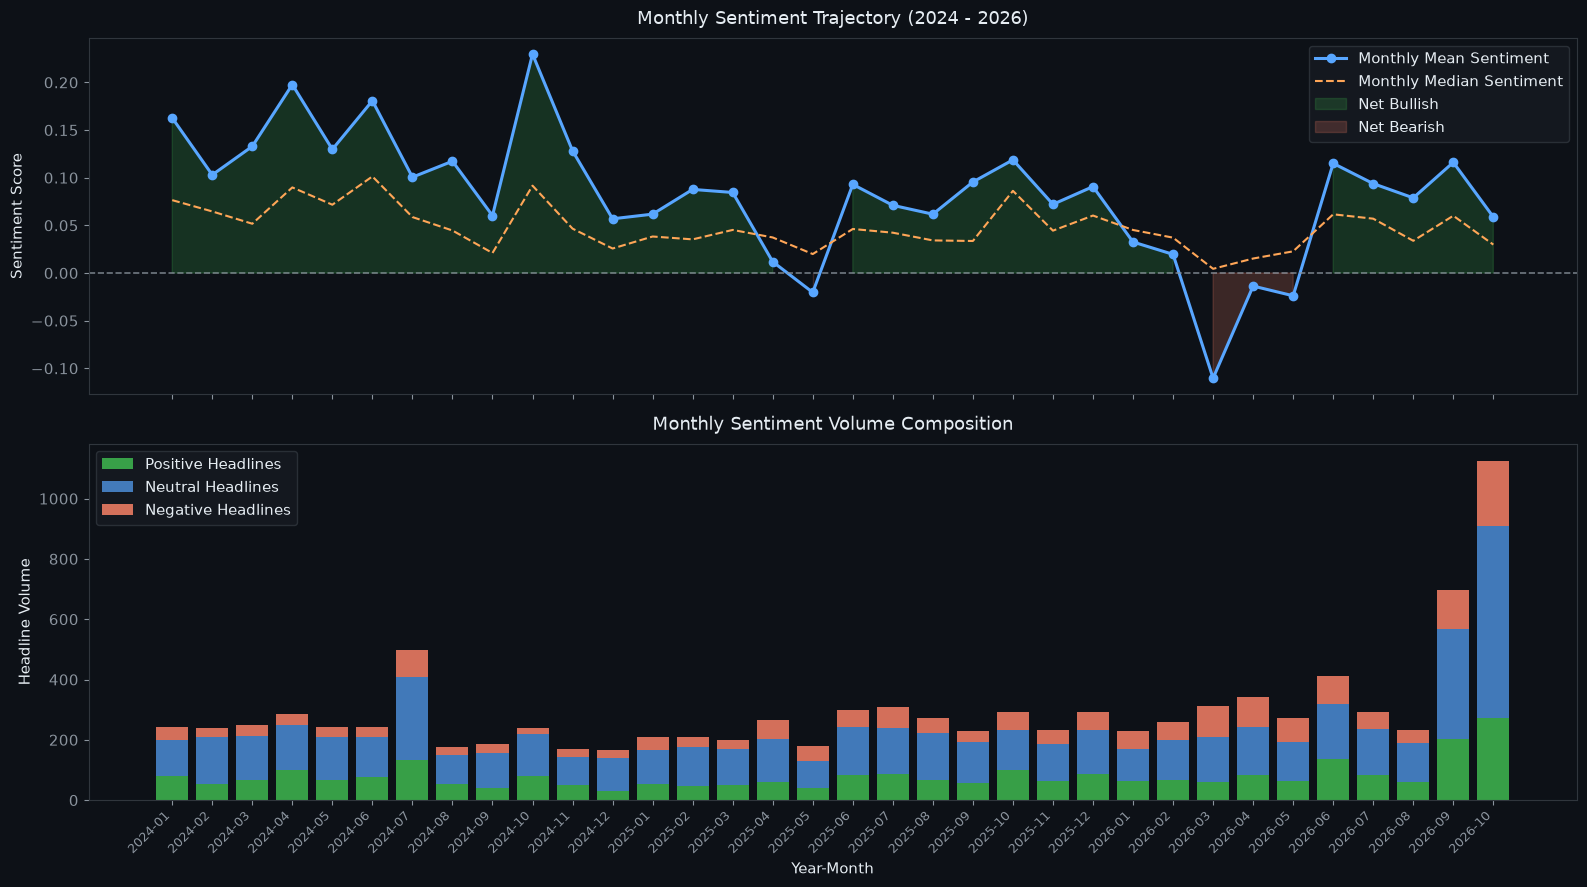

In [11]:
if has_sentiment and 'Published_At' in df.columns:
    df_temp = df.copy()
    df_temp['Date'] = pd.to_datetime(df_temp['Published_At'], errors='coerce')
    df_temp = df_temp.dropna(subset=['Date'])
    df_temp['Month'] = df_temp['Date'].dt.to_period('M').astype(str)
    
    monthly_sent = df_temp.groupby('Month').agg(
        mean_score=('Sentiment_Score', 'mean'),
        median_score=('Sentiment_Score', 'median'),
        pos_count=('Sentiment', lambda x: (x == 'Positive').sum()),
        neg_count=('Sentiment', lambda x: (x == 'Negative').sum()),
        neu_count=('Sentiment', lambda x: (x == 'Neutral').sum()),
        total=('Headlines', 'count')
    ).sort_index()

    fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
    
    # 1. Monthly Mean Sentiment Track
    ax = axes[0]
    months = [str(m) for m in monthly_sent.index]
    x_indices = range(len(months))
    ax.plot(x_indices, monthly_sent['mean_score'], color=ACCENT, marker='o', linewidth=2.2, label='Monthly Mean Sentiment')
    ax.plot(x_indices, monthly_sent['median_score'], color='#ffa657', linestyle='--', linewidth=1.5, label='Monthly Median Sentiment')
    ax.axhline(0.0, color='#8b949e', linestyle='--', linewidth=1.2, alpha=0.8)
    
    # Shading Bullish vs Bearish zones
    ax.fill_between(x_indices, monthly_sent['mean_score'], 0, where=(monthly_sent['mean_score'] >= 0), color=ACCENT2, alpha=0.2, label='Net Bullish')
    ax.fill_between(x_indices, monthly_sent['mean_score'], 0, where=(monthly_sent['mean_score'] < 0), color=ACCENT3, alpha=0.2, label='Net Bearish')
    
    ax.set_title('Monthly Sentiment Trajectory (2024 - 2026)', fontsize=13, pad=10)
    ax.set_ylabel('Sentiment Score')
    ax.legend(facecolor='#161b22', edgecolor='#30363d', labelcolor='#e6edf3', loc='upper right')
    
    # 2. Monthly Positive vs Negative vs Neutral Volume
    ax = axes[1]
    ax.bar(x_indices, monthly_sent['pos_count'], color=ACCENT2, label='Positive Headlines', alpha=0.85)
    ax.bar(x_indices, monthly_sent['neu_count'], bottom=monthly_sent['pos_count'], color=ACCENT, label='Neutral Headlines', alpha=0.7)
    ax.bar(x_indices, monthly_sent['neg_count'], bottom=monthly_sent['pos_count'] + monthly_sent['neu_count'], color=ACCENT3, label='Negative Headlines', alpha=0.85)
    
    ax.set_title('Monthly Sentiment Volume Composition', fontsize=13, pad=10)
    ax.set_xlabel('Year-Month')
    ax.set_ylabel('Headline Volume')
    ax.set_xticks(x_indices)
    ax.set_xticklabels(months, rotation=45, ha='right', fontsize=9)
    ax.legend(facecolor='#161b22', edgecolor='#30363d', labelcolor='#e6edf3', loc='upper left')

    plt.tight_layout()
    save_analysis_fig('analysis_sentiment_temporal.png')
    plt.show()


## 9. Summary Statistics and Clean Export


In [12]:
print('=' * 70)
print('FINAL DATASET SUMMARY (NER + FINBERT SENTIMENT)')
print('=' * 70)
print(f'Total records          : {len(df):,}')
if 'Published_At' in df.columns:
    print(f'Date range             : {df["Published_At"].min()} to {df["Published_At"].max()}')
if 'Source' in df.columns:
    print(f'Unique sources         : {df["Source"].nunique()}')
if has_ner:
    n_rel = int((df['Interest'] == 1).sum())
    n_irr = int((df['Interest'] == 0).sum())
    pct = n_rel / len(df) * 100
    print(f'Relevant (Interest=1)  : {n_rel:,} ({pct:.1f}%)')
    print(f'Filtered  (Interest=0) : {n_irr:,} ({100-pct:.1f}%)')
    sec_clean = df['Sector'].replace('None', np.nan).dropna()
    com_clean = df['Company'].replace('None', np.nan).dropna()
    print(f'Unique sectors         : {sec_clean.nunique()}')
    print(f'Unique companies       : {com_clean.nunique():,}')
    print()
    print('Top 10 Sectors:')
    print(sec_clean.value_counts().head(10).to_string())
    print()
    print('Top 15 Companies:')
    print(com_clean.value_counts().head(15).to_string())

if has_sentiment:
    print('Sentiment Distribution:')
    print(df['Sentiment'].value_counts().to_string())
    print(f'Mean Sentiment Score   : {df["Sentiment_Score"].mean():+.3f}')
    print(f'Median Sentiment Score : {df["Sentiment_Score"].median():+.3f}')

print('=' * 70)

drop_cols = [c for c in ['Month', 'Year', 'DayOfWeek'] if c in df.columns]
df_export = df.drop(columns=drop_cols)
out_path = os.path.join(project_root, 'Datasets', 'financial_news_ner_annotated_clean.csv')
df_export.to_csv(out_path, index=False)
print(f'Clean annotated dataset exported to: {out_path}')
print(f'Shape: {df_export.shape}')


FINAL DATASET SUMMARY (NER + FINBERT SENTIMENT)
Total records          : 10,106
Date range             : 2024-01-01 08:00:00 to 2026-10-12 15:53:29
Unique sources         : 56
Relevant (Interest=1)  : 7,647 (75.7%)
Filtered  (Interest=0) : 2,459 (24.3%)
Unique sectors         : 93
Unique companies       : 1,625

Top 10 Sectors:
Sector
Macro / Economy           2389
Banking                   2297
Information Technology    1202
Energy                     946
Financial Services         457
FMCG                       404
Infrastructure             396
Telecom                    281
Automotive                 163
Real Estate                122

Top 15 Companies:
Company
Reliance Industries          712
HDFC Bank                    445
Infosys                      306
State Bank of India          263
Tata Consultancy Services    246
ICICI Bank                   114
TCS                          107
Reserve Bank of India         84
RBI                           81
Multiple                     

Clean annotated dataset exported to: /mnt/c/Users/arnav/OneDrive/Documents/Self_Apps/Stock-Market-Prediction/Datasets/financial_news_ner_annotated_clean.csv
Shape: (10106, 13)
